# CLV error analysis

Test set: features as of **2011-06-01**, target = revenue **Jun–Nov 2011**. Models were trained on features as of 2010-12-01 (target Dec 2010–May 2011).

The question isn't just "which model has the lowest MAE" — it's **where the model is wrong, and what that costs the business**.

In [1]:
import joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
import os; os.chdir('..') if os.path.basename(os.getcwd()) == 'clv' else None

df = pd.read_parquet('data/test_predictions.parquet')
best = joblib.load('models/clv.joblib')['name']
y = df.target
P = {'baseline': df.pred_baseline_last_6m, best: df[f'pred_{best}']}
print(f'{len(df):,} customers, best model = {best}')
pd.read_json('models/metrics.json', orient='index').round(3)

4,338 customers, best model = random_forest


,MAE,RMSE,top20_capture,top10_lift,total_bias
baseline_last_6m,643.393,3233.311,0.724,5.991,-0.210
ridge_log,1014.956,11264.536,0.724,5.901,-0.410
random_forest,697.490,4260.188,0.737,6.152,-0.416
lgbm_tweedie,670.253,3816.913,0.735,6.150,-0.487


## 1. Zero inflation: most customers don't come back

In [2]:
print(f"{(y == 0).mean():.0%} of customers spend £0 in the next 6 months")
print(f"Top 1% of customers = {y.nlargest(len(y)//100).sum() / y.sum():.0%} of future revenue")
for n, p in P.items():
    print(f"{n:15s} AUC for 'buys again': {roc_auc_score(y > 0, p):.3f} | "
          f"mean prediction for customers who spent £0: £{p[y == 0].mean():,.0f}")

43% of customers spend £0 in the next 6 months
Top 1% of customers = 36% of future revenue
baseline        AUC for 'buys again': 0.735 | mean prediction for customers who spent £0: £271
random_forest   AUC for 'buys again': 0.754 | mean prediction for customers who spent £0: £212


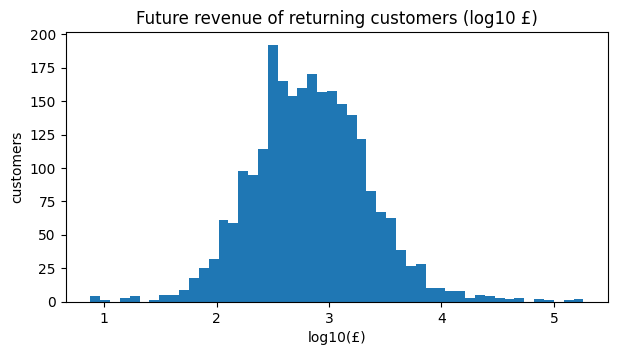

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(y[y > 0]), bins=50)
ax.set(title='Future revenue of returning customers (log10 £)', xlabel='log10(£)', ylabel='customers');

## 2. Calibration by predicted decile — is the model biased, and where?

baseline         random_forest        
       pred  actual          pred  actual
1       0.0   294.0          27.0    85.0
2       0.0   201.0          52.0   132.0
3       0.0   218.0          85.0   159.0
4      20.0   184.0         128.0   260.0
5     152.0   262.0         176.0   315.0
6     273.0   342.0         218.0   343.0
7     409.0   505.0         279.0   512.0
8     658.0   710.0         435.0   781.0
9    1147.0  1232.0         770.0  1194.0
10   5116.0  5897.0        3581.0  6065.0

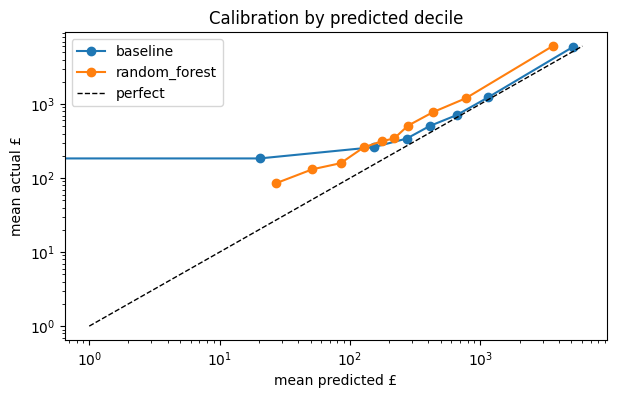

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
calib = {}
for n, p in P.items():
    dec = pd.qcut(p.rank(method='first'), 10, labels=range(1, 11))
    c = pd.DataFrame({'pred': p, 'actual': y}).groupby(dec, observed=True).mean()
    calib[n] = c
    ax.plot(c.pred, c.actual, 'o-', label=n)
lim = max(c.max().max() for c in calib.values())
ax.plot([1, lim], [1, lim], 'k--', lw=1, label='perfect')
ax.set(xscale='log', yscale='log', xlabel='mean predicted £', ylabel='mean actual £', title='Calibration by predicted decile')
ax.legend()
pd.concat(calib, axis=1).round(0)

In [5]:
print(f"Actual total revenue:  £{y.sum():,.0f}")
for n, p in P.items():
    print(f"{n:15s} predicted £{p.sum():,.0f}  ({p.sum() / y.sum() - 1:+.0%})")
tx = pd.read_parquet('data/transactions.parquet')
m = tx.set_index('date').revenue.resample('MS').sum()
print('\nMonthly revenue (all customers) — note the autumn peak:')
print((m / 1e3).round(0).astype(int).to_string())

Actual total revenue:  £4,272,260
baseline        predicted £3,374,226  (-21%)
random_forest   predicted £2,495,292  (-42%)

Monthly revenue (all customers) — note the autumn peak:
date
2009-12-01     684
2010-01-01     556
2010-02-01     505
2010-03-01     697
2010-04-01     592
2010-05-01     598
2010-06-01     636
2010-07-01     590
2010-08-01     602
2010-09-01     829
2010-10-01    1033
2010-11-01    1166
2010-12-01     570
2011-01-01     568
2011-02-01     446
2011-03-01     594
2011-04-01     468
2011-05-01     677
2011-06-01     660
2011-07-01     599
2011-08-01     644
2011-09-01     951
2011-10-01    1036
2011-11-01    1156
2011-12-01     517
Freq: MS


## 3. Segments — who is the model wrong about?

In [6]:
seg = pd.DataFrame({
    'segment_new_vs_repeat': np.where(df.frequency == 1, 'one-time buyer', 'repeat buyer'),
    'segment_country': np.where(df.is_uk == 1, 'UK', 'non-UK'),
    'segment_recency': pd.cut(df.recency_days, [-1, 30, 90, 180, 366], labels=['<30d', '30-90d', '90-180d', '180d+']),
}, index=df.index)

def seg_table(col):
    rows = []
    for g, idx in df.groupby(seg[col], observed=True).groups.items():
        r = {'segment': g, 'customers': len(idx), 'actual_mean': y[idx].mean()}
        for n, p in P.items():
            r[f'{n}_MAE'] = (p[idx] - y[idx]).abs().mean()
            r[f'{n}_bias'] = p[idx].sum() / y[idx].sum() - 1
        rows.append(r)
    return pd.DataFrame(rows).set_index('segment').round(2)

for col in seg:
    display(seg_table(col))

,customers,actual_mean,baseline_MAE,baseline_bias,random_forest_MAE,random_forest_bias
segment,,,,,,
one-time buyer,1548,193.06,232.33,-0.37,219.02,-0.47
repeat buyer,2790,1424.16,871.47,-0.20,962.96,-0.41


,customers,actual_mean,baseline_MAE,baseline_bias,random_forest_MAE,random_forest_bias
segment,,,,,,
UK,3969,869.49,589.82,-0.20,611.49,-0.38
non-UK,369,2225.63,1219.64,-0.25,1622.56,-0.58


,customers,actual_mean,baseline_MAE,baseline_bias,random_forest_MAE,random_forest_bias
segment,,,,,,
<30d,1056,2669.74,1296.94,-0.20,1595.73,-0.44
30-90d,922,754.00,621.19,0.03,580.25,-0.34
90-180d,712,530.93,651.09,0.01,543.26,-0.39
180d+,1648,230.46,233.71,-0.97,254.14,-0.40


## 4. Biggest misses

In [7]:
cols = ['recency_days', 'frequency', 'monetary', 'revenue_last_6m', 'is_uk', 'target', f'pred_{best}']
err = df[f'pred_{best}'] - y
print('Most UNDER-predicted (missed revenue):')
display(df.loc[err.nsmallest(8).index, cols].round(0))
print('Most OVER-predicted (would waste retention spend):')
display(df.loc[err.nlargest(8).index, cols].round(0))

Most UNDER-predicted (missed revenue):


,recency_days,frequency,monetary,revenue_last_6m,is_uk,target,pred_random_forest
customer_id,,,,,,,
18102,14,55,231406.0,64642.0,1,183530.0,23761.0
14646,5,71,253571.0,115671.0,0,157765.0,23761.0
17450,0,19,106154.0,55760.0,1,137068.0,23739.0
14911,5,187,129978.0,38795.0,0,97938.0,23761.0
12415,11,14,70428.0,50884.0,0,74031.0,23734.0
14156,15,72,135339.0,43892.0,0,73318.0,23761.0
14088,130,4,21090.0,7545.0,1,42947.0,6053.0
17949,0,39,33732.0,9059.0,1,46577.0,12325.0


Most OVER-predicted (would waste retention spend):


,recency_days,frequency,monetary,revenue_last_6m,is_uk,target,pred_random_forest
customer_id,,,,,,,
12346,133,2,77326.0,77184.0,1,0.0,23730.0
15749,43,3,44534.0,44534.0,1,0.0,23730.0
17381,11,25,29941.0,13818.0,1,6149.0,18328.0
13093,83,38,40422.0,9415.0,1,0.0,11851.0
13798,4,59,43948.0,22293.0,1,13024.0,23761.0
16754,180,15,35635.0,2002.0,1,0.0,10620.0
17850,180,94,24738.0,5391.0,1,0.0,8717.0
13081,25,16,28619.0,14464.0,1,13874.0,21130.0


## 5. What it means in £ — targeting the top 20%

Scenario: marketing can afford a retention campaign for **20% of customers**. Each model picks who. The gains curve shows how much future revenue sits inside the chosen group.

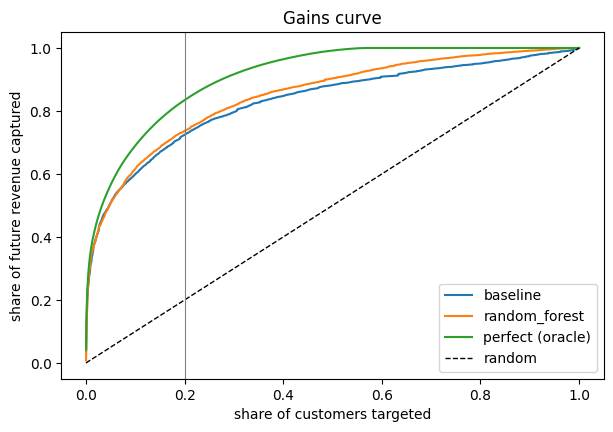

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(1, len(y) + 1) / len(y)
for n, p in {**P, 'perfect (oracle)': y}.items():
    ax.plot(x, y.values[np.argsort(-p.values)].cumsum() / y.sum(), label=n)
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='random')
ax.axvline(0.2, color='grey', lw=0.8)
ax.set(xlabel='share of customers targeted', ylabel='share of future revenue captured', title='Gains curve')
ax.legend();

In [9]:
k = len(y) // 5
oracle = y.nlargest(k).sum()
for n, p in P.items():
    got = y[p.nlargest(k).index].sum()
    print(f"{n:15s} targets £{got:,.0f} of future revenue  | vs oracle: £{oracle - got:,.0f} left out")
a, b = (set(p.nlargest(k).index) for p in P.values())
print(f"\nThe two top-20% lists overlap on {len(a & b) / k:.0%} of customers")

baseline        targets £3,093,377 of future revenue  | vs oracle: £471,403 left out
random_forest   targets £3,146,999 of future revenue  | vs oracle: £417,781 left out

The two top-20% lists overlap on 83% of customers


## Findings

**1. The model is a better *ranker*, not a better *forecaster*.**
Random Forest's top-20% list holds £3.15M of next-period revenue vs £3.09M for the "last 6 months repeats" baseline (+£54k), and it's better at telling who comes back at all (AUC 0.754 vs 0.735). But its MAE is worse (697 vs 643). For a retention budget decision — *who* to target — ranking is what matters. For a revenue *forecast*, don't use this model as-is.

**2. Every prediction is too low, and it's seasonality, not a bug.**
Models predict 42% less revenue than happened. Training labels came from Dec–May; the test window is Jun–Nov, which contains the Sep–Nov wholesale peak (monthly revenue ~1.7× the spring months, visible in both years). The model learned "spring-sized" spend. The model gets hit twice: in training it learned to map 12 months of history (which includes a peak) to an off-season label, so it learned to *shrink*; then it's asked to predict a peak season. The baseline is only hit once (off-season input → peak target), hence −21%. Fix: train on a cutoff whose target window is the same season (needs 2+ years of history), or add a seasonal multiplier calibrated on last year.

**3. Trees can't predict whales.**
The six most under-predicted customers each spent £74k–£184k but were predicted at a flat ~£23.7k — the Random Forest's ceiling, because leaf averages can't go above what the training data shows. 36% of future revenue sits with 1% of customers, so these few misses dominate RMSE. For the top accounts, a key-account manager beats any model; or try a model that can extrapolate (e.g. linear on log scale per segment).

**4. The baseline is blind to reactivation.**
Customers silent for 180+ days get a baseline prediction of £0, yet they spend £230 on average (baseline bias −97% for that segment). The model sees recency/tenure and catches part of it. That's where the model's ranking gain comes from.

**5. Expensive false positives are one-off bulk buyers.**
The biggest over-predictions (e.g. £77k and £45k in 2–3 orders, then nothing) are wholesale one-offs. A rule like "frequency ≤ 3 and a single order > 80% of spend" would flag them before spending retention money.

**Business takeaway:** use the model to rank customers for retention spend (it beats the naive rule by ~£54k per campaign cycle on this data), keep a manual list for the top ~1% of accounts, and don't quote its totals as a revenue forecast without a seasonal correction. The gap to a perfect oracle is still £418k — there's real room for better features (product mix, order-interval trends).